Name: Ming Jia Zang
<br>
Github Username: mzang20
<br>
USC ID: 7754553096

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [78]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, roc_auc_score

Get the AReM Data Set

In [79]:
data_path = Path("data/AReM")
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
data = {}

for activity in activities:
    folder = data_path / activity
    for file in folder.glob("dataset*.csv"):
        rows = []
        with open(file, encoding="utf-8-sig") as f:
            for line in f:
                if line.startswith("#"):
                    continue
                values = line.strip().replace(";", ",").replace("\t", ",").split(",")
                try:
                    numbers = [float(value) for value in values if value.strip()]
                    if len(numbers) in (6, 7):
                        rows.append(numbers[-6:])
                except ValueError:
                    continue
        data[file] = pd.DataFrame(rows)

print("Total files:", len(data))

Total files: 88


### (b) Splitting Data

In [80]:
train_files = []
test_files = []

for activity in activities:
    folder = data_path / activity
    if activity == "bending1" or activity == "bending2":
        test_limit = 2
    else:
        test_limit = 3

    for file in folder.glob("dataset*.csv"):
        number = int(file.stem.replace("dataset", ""))
        if number <= test_limit:
            test_files.append(file)
        else:
            train_files.append(file)

train_files.sort()
test_files.sort()
y_train = np.array([int(file.parent.name.startswith("bending")) for file in train_files])
y_test = np.array([int(file.parent.name.startswith("bending")) for file in test_files])

print("Train:", len(train_files))
print("Test:", len(test_files))

Train: 69
Test: 19


In [81]:
data = {}

for file in train_files + test_files:
    if file.parent.name == "bending2" and file.name == "dataset4.csv":
        df = pd.read_csv(file, skiprows=5, sep=r"\s+", header=None)
    else:
        df = pd.read_csv(file, skiprows=5, header=None, usecols=range(7))

    data[file] = df.iloc[:, 1:]

### (c) Feature Extraction

i. Common time-domain features include minimum, maximum, mean, median, standard deviation, variance, quartiles, range, interquartile range, skewness, and kurtosis.

iv. I chose minimum, mean, and maximum because they describe the lowest, typical, and highest values in each time series.

In [82]:
stats = ["min", "max", "mean", "median", "std", "q1", "q3"]

def extract_features(files, l=1, simple=False):
    result = []
    for file in files:
        row = []
        for indices in np.array_split(range(len(data[file])), l):
            part = data[file].iloc[indices]
            for sensor in range(6):
                values = part.iloc[:, sensor]
                if simple:
                    row.extend([values.min(), values.mean(), values.max()])
                else:
                    row.extend([values.min(), values.max(), values.mean(),
                                values.median(), values.std(),
                                values.quantile(0.25), values.quantile(0.75)])
        result.append(row)
    return pd.DataFrame(result)

column_names = []
for sensor in range(1, 7):
    for stat in stats:
        column_names.append(f"{stat}{sensor}")

all_features = extract_features(train_files + test_files)
all_features.columns = column_names
print(all_features.shape)
display(all_features.head())

np.random.seed(42)
bootstrap_std = []
for i in range(1000):
    sample = all_features.sample(n=len(all_features), replace=True)
    bootstrap_std.append(sample.std())

bootstrap_std = pd.DataFrame(bootstrap_std)
intervals = pd.DataFrame({
    "std": all_features.std(),
    "lower_90%": bootstrap_std.quantile(0.05),
    "upper_90%": bootstrap_std.quantile(0.95)
})
display(intervals)

(88, 42)


,min1,max1,mean1,median1,std1,q11,q31,min2,max2,mean2,...,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
2,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
3,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
4,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83


,std,lower_90%,upper_90%
min1,9.569975,8.275241,10.747623
max1,4.394362,3.343823,5.296316
mean1,5.335718,4.686470,5.869648
median1,5.440054,4.788491,6.016169
std1,1.772153,1.569967,1.945903
q11,6.153590,5.547790,6.646684
q31,5.138925,4.330721,5.825098
min2,0.000000,0.000000,0.000000
max2,5.062729,4.645742,5.403547
mean2,1.574164,1.411542,1.710131


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

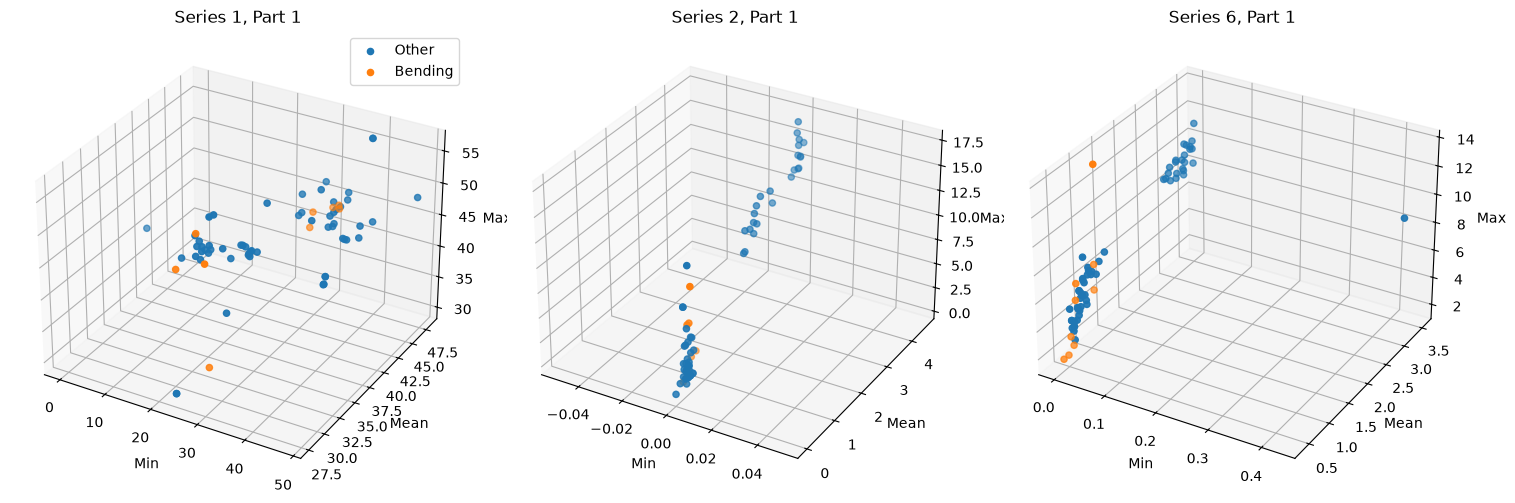

In [83]:
def plot_features(l):
    X = extract_features(train_files, l, simple=True)
    fig = plt.figure(figsize=(15, 5 * l))

    for part in range(l):
        for j, sensor in enumerate([1, 2, 6]):
            ax = fig.add_subplot(l, 3, part * 3 + j + 1, projection="3d")
            start = part * 18 + (sensor - 1) * 3
            for label, name in [(0, "Other"), (1, "Bending")]:
                points = X.loc[y_train == label].iloc[:, start:start + 3]
                ax.scatter(points.iloc[:, 0], points.iloc[:, 1], points.iloc[:, 2], label=name)
            ax.set_xlabel("Min")
            ax.set_ylabel("Mean")
            ax.set_zlabel("Max")
            ax.set_title(f"Series {sensor}, Part {part + 1}")
    fig.axes[0].legend()
    plt.tight_layout()
    plt.show()

plot_features(1)

#### ii. Splitted Plots

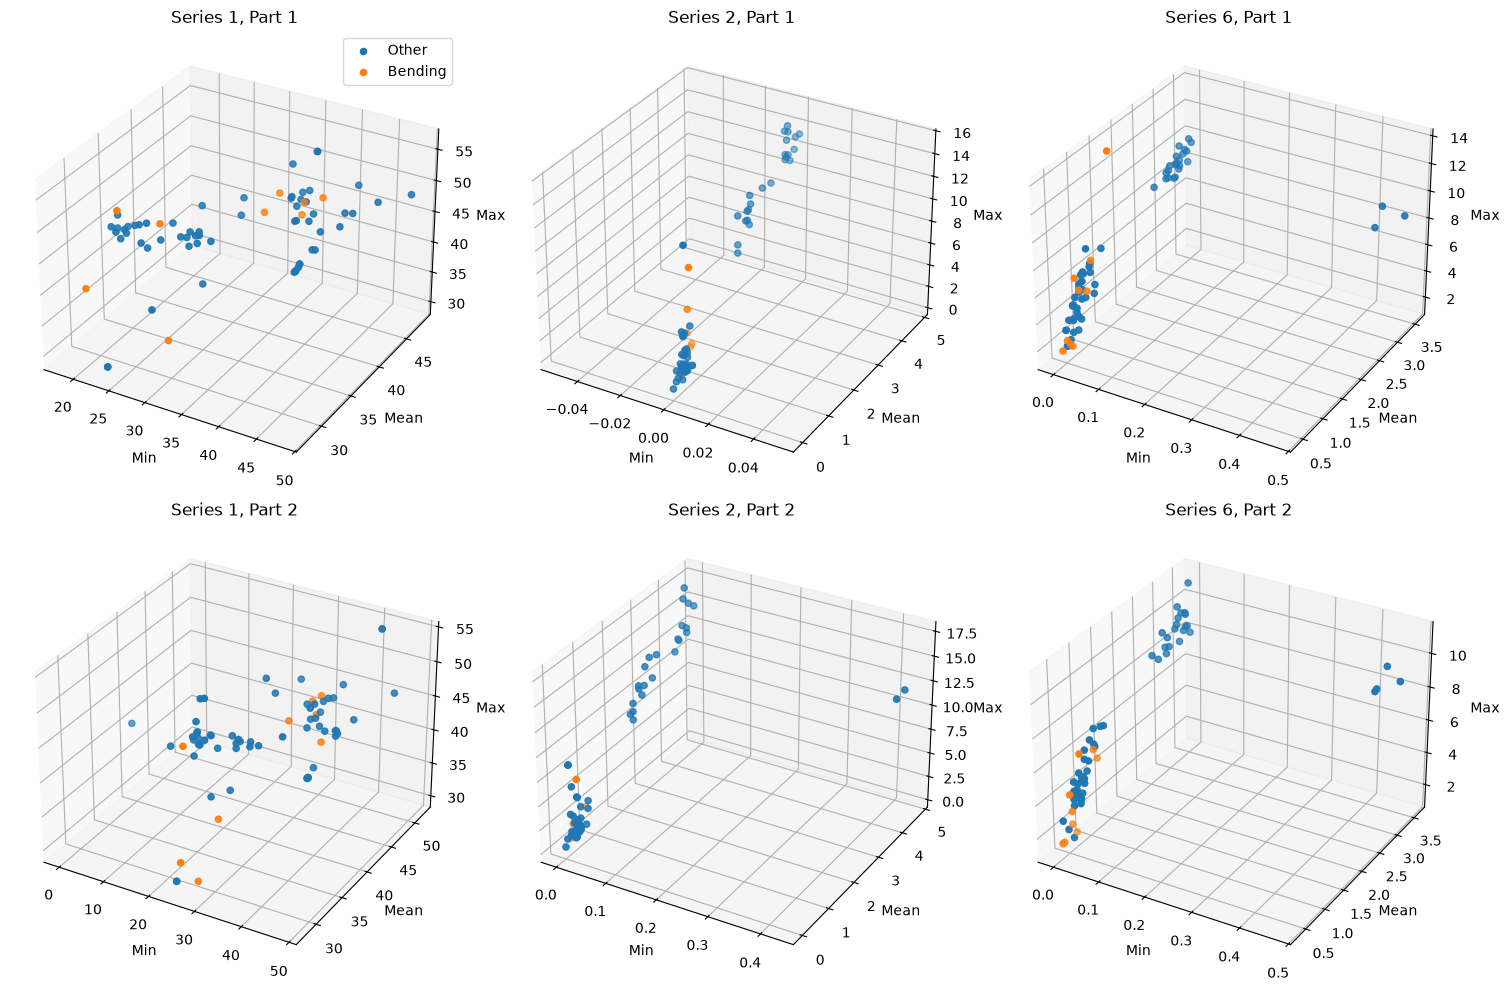

In [84]:
plot_features(2)

Splitting the time series into two parts does not show a considerable improvement in separating bending from other activities. The classes still overlap in several areas, although splitting provides more detailed features for each instance.

#### iii. Time Series Segments

The wrong way is to select features on the whole training set and then cross-validate only the final model. The validation folds have then already influenced which features were chosen, so the CV accuracy comes out too optimistic. The right way is to put scaling and feature selection inside each fold, using only that fold’s training data. A pipeline inside cross_val_score does this. The classes are imbalanced, so I used stratified 5-fold CV.

In [85]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_features = {}
test_features = {}

for l in range(1, 21):
    train_features[l] = extract_features(train_files, l)
    test_features[l] = extract_features(test_files, l)

best_score = 0
best_l = 1
best_p = 3

for l in range(1, 21):
    for p in [3, 6, 9, 12]:
        logistic = LogisticRegression(C=1000000, max_iter=1000)
        model = make_pipeline(StandardScaler(), RFE(logistic, n_features_to_select=p, step=0.5), logistic)
        score = cross_val_score(model, train_features[l], y_train, cv=cv).mean()

        if score > best_score:
            best_score = score
            best_l = l
            best_p = p

print("Best l:", best_l)
print("Best p:", best_p)
print("CV accuracy:", best_score)

Best l: 1
Best p: 3
CV accuracy: 0.9857142857142858


#### iv. Confusion Matrix

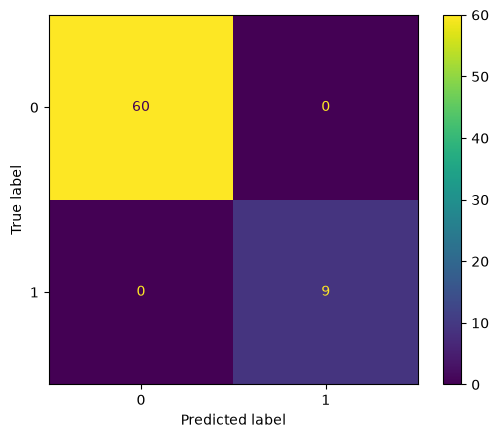

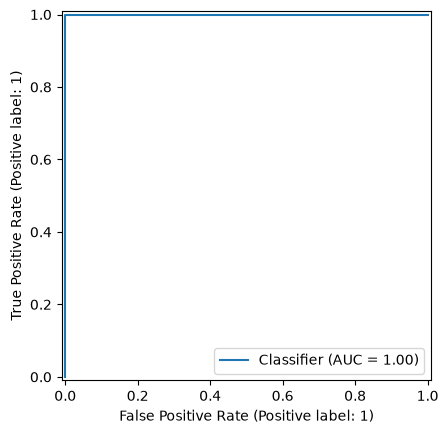

Train accuracy: 1.0
Train AUC: 1.0


c:\Users\mingj\OneDrive\Desktop\DSCI552\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\mingj\OneDrive\Desktop\DSCI552\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
c:\Users\mingj\OneDrive\Desktop\DSCI552\.venv\Lib\site-packages\statsmodels\genmod\generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,coefficient,p_value
intercept,-100.233847,0.998935
q31_part1,-28.456474,0.999739
min5_part1,51.140025,0.999719
max5_part1,61.622991,0.999549


In [86]:
logistic = LogisticRegression(C=1000000, max_iter=1000)
model = make_pipeline(StandardScaler(), RFE(logistic, n_features_to_select=best_p, step=0.5), logistic)
model.fit(train_features[best_l], y_train)

predictions = model.predict(train_features[best_l])
probabilities = model.predict_proba(train_features[best_l])[:, 1]

ConfusionMatrixDisplay.from_predictions(y_train, predictions)
plt.show()
RocCurveDisplay.from_predictions(y_train, probabilities)
plt.show()
print("Train accuracy:", accuracy_score(y_train, predictions))
print("Train AUC:", roc_auc_score(y_train, probabilities))

feature_names = []
for part in range(1, best_l + 1):
    for sensor in range(1, 7):
        for stat in stats:
            feature_names.append(f"{stat}{sensor}_part{part}")

selected = model.named_steps["rfe"].support_
selected_names = np.array(feature_names)[selected]
scaled = model.named_steps["standardscaler"].transform(train_features[best_l])
selected_features = scaled[:, selected]

try:
    fit = sm.GLM(y_train, sm.add_constant(selected_features), family=sm.families.Binomial()).fit()
    results = pd.DataFrame({"coefficient": fit.params, "p_value": fit.pvalues},
                           index=["intercept"] + list(selected_names))
    display(results)
except Exception as e:
    print("P-values could not be calculated:", e)
    print("Intercept:", model.named_steps["logisticregression"].intercept_)
    print("Coefficients:", model.named_steps["logisticregression"].coef_)

The p-values are all close to 1 because the classes are perfectly separated. The coefficients and standard errors blow up, so these p-values are not meaningful.

#### v. Test Classifier

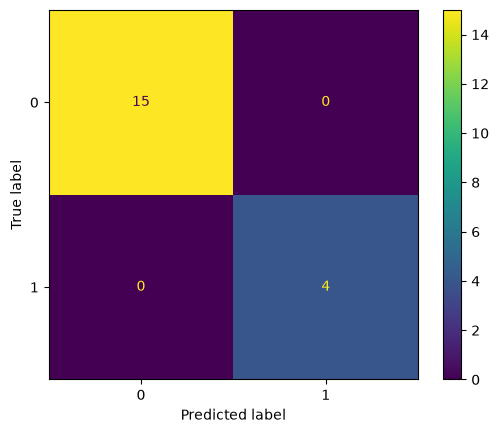

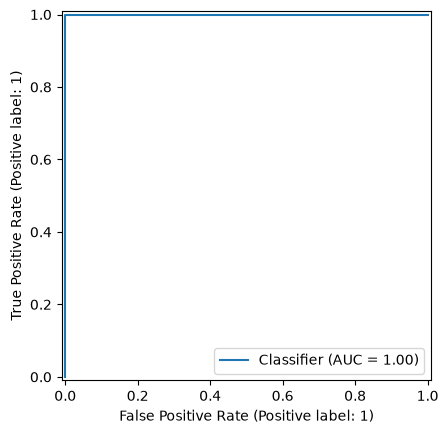

Test accuracy: 1.0
Cross-validation accuracy: 0.9857142857142858


In [87]:
test_predictions = model.predict(test_features[best_l])
test_probabilities = model.predict_proba(test_features[best_l])[:, 1]

ConfusionMatrixDisplay.from_predictions(y_test, test_predictions)
plt.show()
RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.show()

print("Test accuracy:", accuracy_score(y_test, test_predictions))
print("Cross-validation accuracy:", best_score)

The test accuracy (1.0) is slightly higher than the CV accuracy (0.986). With only 19 test instances, the two are effectively the same.

#### vi. Separation

The classes appear to be perfectly separated because the training accuracy and AUC are both 1.0. The perfect separation warnings suggest that the logistic regression coefficients and p-values may be unstable.

#### vii. Imbalance

Yes, the classes are imbalanced: 9 bending vs. 60 other instances in the training set.

Class counts: [60  9]


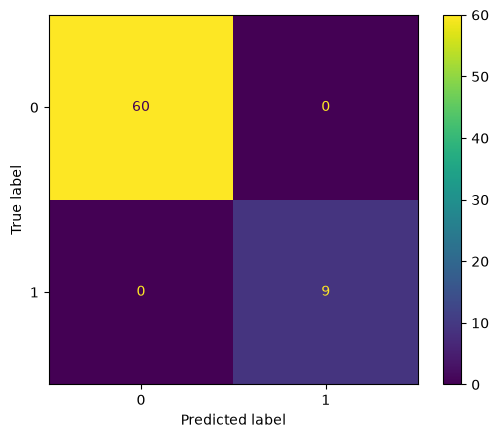

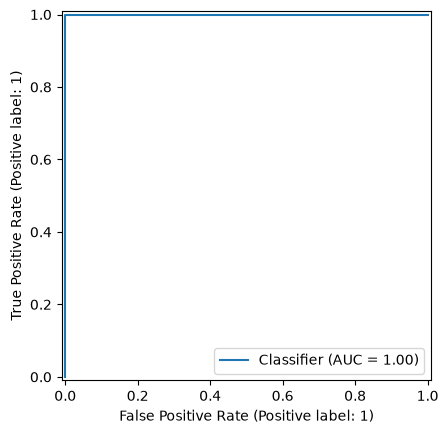

Train AUC: 1.0


In [88]:
print("Class counts:", np.bincount(y_train))

np.random.seed(42)
bending_indices = np.where(y_train == 1)[0]
other_indices = np.where(y_train == 0)[0]
chosen_other = np.random.choice(other_indices, size=len(bending_indices), replace=False)
sample_indices = np.concatenate([bending_indices, chosen_other])

logistic = LogisticRegression(C=1000000, max_iter=1000)
case_model = make_pipeline(StandardScaler(), RFE(logistic, n_features_to_select=best_p, step=0.5), logistic)
case_model.fit(train_features[best_l].iloc[sample_indices], y_train[sample_indices])

original_rate = y_train.mean()
case_model.named_steps["logisticregression"].intercept_[0] += np.log(original_rate / (1 - original_rate))

case_predictions = case_model.predict(train_features[best_l])
case_probabilities = case_model.predict_proba(train_features[best_l])[:, 1]
ConfusionMatrixDisplay.from_predictions(y_train, case_predictions)
plt.show()
RocCurveDisplay.from_predictions(y_train, case_probabilities)
plt.show()
print("Train AUC:", roc_auc_score(y_train, case_probabilities))

The case-control model, with its intercept adjusted by log(π/(1−π)), still reaches a training AUC of 1.0.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [89]:
l1_best_score = 0
l1_best_l = 1
l1_best_C = 1

for l in range(1, 21):
    for C in [0.01, 0.1, 1, 10]:
        model_l1 = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, C=C,
                                                                      solver="liblinear", max_iter=1000))
        score = cross_val_score(model_l1, train_features[l], y_train, cv=cv).mean()
        if score > l1_best_score:
            l1_best_score = score
            l1_best_l = l
            l1_best_C = C

model_l1 = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, C=l1_best_C,
                                                              solver="liblinear", max_iter=1000))
model_l1.fit(train_features[l1_best_l], y_train)
l1_predictions = model_l1.predict(test_features[l1_best_l])

print("Best l:", l1_best_l)
print("Best C:", l1_best_C)
print("L1 CV accuracy:", l1_best_score)
print("L1 test accuracy:", accuracy_score(y_test, l1_predictions))
print("RFE CV accuracy:", best_score)

Best l: 2
Best C: 10
L1 CV accuracy: 0.9714285714285715
L1 test accuracy: 0.9473684210526315
RFE CV accuracy: 0.9857142857142858


#### ii. Comparison

Logistic regression with RFE performed slightly better, achieving 98.57% cross-validation accuracy compared to 97.14% for L1 logistic regression. L1 logistic regression is easier to implement because feature selection is performed automatically through regularization.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Best l: 1
Best C: 10
Test error: 0.052631578947368474


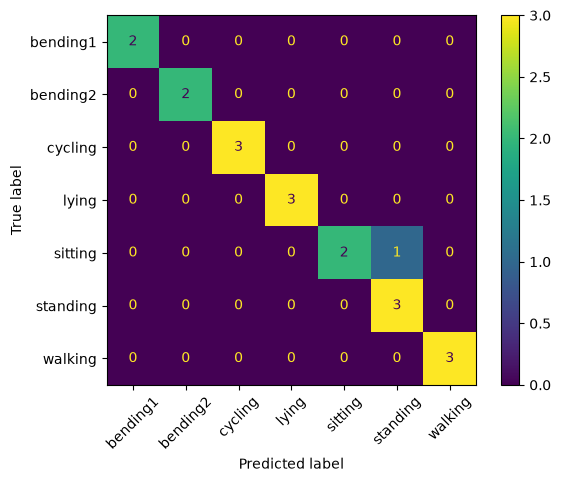

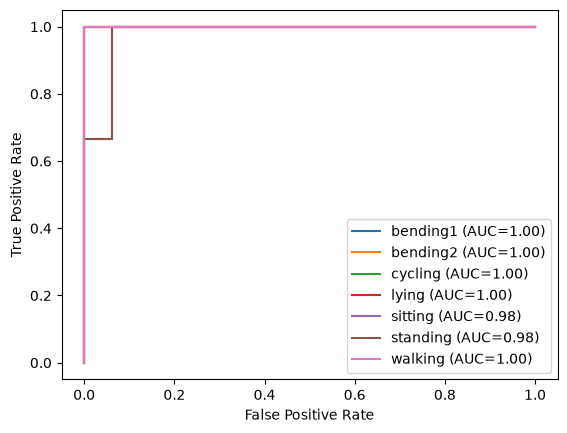

Macro AUC: 0.9940476190476192


In [90]:
y_multi_train = np.array([file.parent.name for file in train_files])
y_multi_test = np.array([file.parent.name for file in test_files])
cv_multi = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

multi_best_score = 0
multi_best_l = 1
multi_best_C = 1

for l in range(1, 21):
    for C in [0.01, 0.1, 1, 10]:
        multi_model = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, C=C, solver="saga", max_iter=10000))
        score = cross_val_score(multi_model, train_features[l], y_multi_train, cv=cv_multi).mean()
        if score > multi_best_score:
            multi_best_score = score
            multi_best_l = l
            multi_best_C = C

multi_model = make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1, C=multi_best_C, solver="saga", max_iter=10000))
multi_model.fit(train_features[multi_best_l], y_multi_train)
multi_predictions = multi_model.predict(test_features[multi_best_l])
multi_probabilities = multi_model.predict_proba(test_features[multi_best_l])
multi_error = 1 - accuracy_score(y_multi_test, multi_predictions)

print("Best l:", multi_best_l)
print("Best C:", multi_best_C)
print("Test error:", multi_error)
ConfusionMatrixDisplay.from_predictions(y_multi_test, multi_predictions, xticks_rotation=45)
plt.show()

for i, activity in enumerate(multi_model.classes_):
    fpr, tpr, _ = roc_curve(y_multi_test == activity, multi_probabilities[:, i])
    auc = roc_auc_score(y_multi_test == activity, multi_probabilities[:, i])
    plt.plot(fpr, tpr, label=f"{activity} (AUC={auc:.2f})")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()
print("Macro AUC:", roc_auc_score(y_multi_test, multi_probabilities, multi_class="ovr", labels=multi_model.classes_))

I used 4-fold stratified CV because bending2 has only 4 training instances.

For K classes, the confusion matrix is K×K: entry (i, j) counts instances of class i predicted as class j. ROC curves are drawn one-vs-rest. Each class is treated as positive and all the others as negative, which gives one ROC curve and AUC per class.

#### ii. Naive Bayes

Gaussian best l: 1 CV accuracy: 0.8562091503267973 test error: 0.10526315789473684


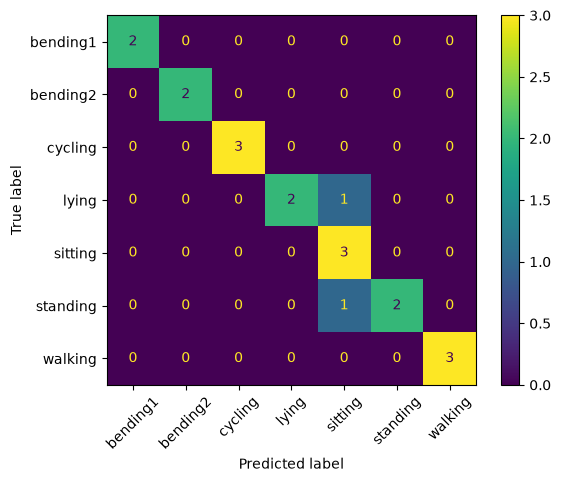

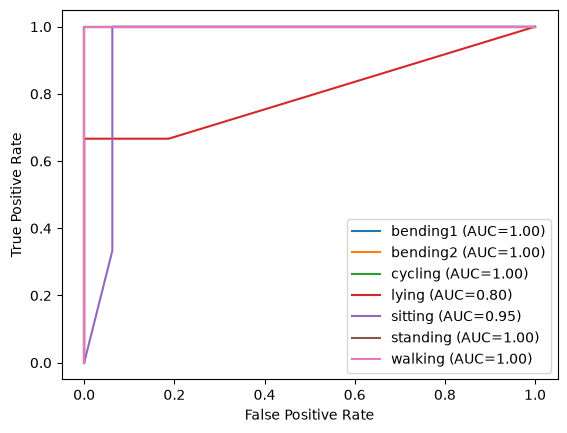

Gaussian macro AUC: 0.9642857142857143
Multinomial best l: 2 CV accuracy: 0.7671568627450981 test error: 0.21052631578947367


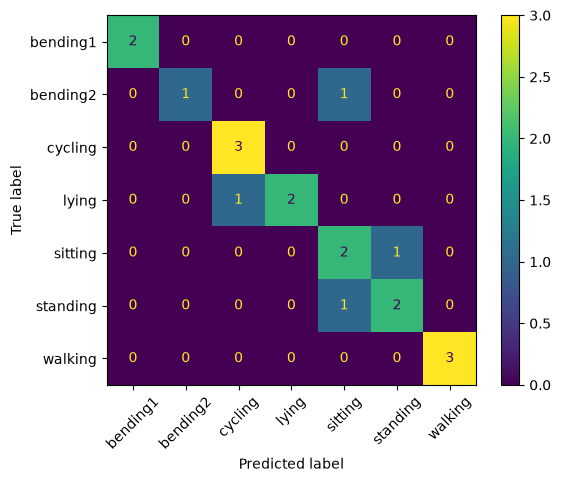

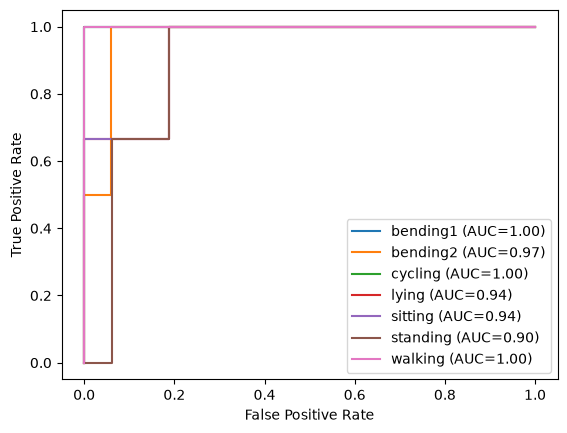

Multinomial macro AUC: 0.9630602240896359


In [91]:
nb_results = []

for name in ["Gaussian", "Multinomial"]:
    best_nb_score = 0
    best_nb_l = 1

    for l in range(1, 21):
        if name == "Gaussian":
            nb_model = GaussianNB()
        else:
            nb_model = make_pipeline(MinMaxScaler(clip=True), MultinomialNB())

        score = cross_val_score(nb_model, train_features[l], y_multi_train, cv=cv_multi).mean()
        if score > best_nb_score:
            best_nb_score = score
            best_nb_l = l

    nb_model.fit(train_features[best_nb_l], y_multi_train)
    predictions = nb_model.predict(test_features[best_nb_l])
    probabilities = nb_model.predict_proba(test_features[best_nb_l])
    error = 1 - accuracy_score(y_multi_test, predictions)
    nb_results.append((name, best_nb_l, best_nb_score, error))

    print(name, "best l:", best_nb_l, "CV accuracy:", best_nb_score, "test error:", error)
    ConfusionMatrixDisplay.from_predictions(y_multi_test, predictions, xticks_rotation=45)
    plt.show()

    for i, activity in enumerate(nb_model.classes_):
        fpr, tpr, _ = roc_curve(y_multi_test == activity, probabilities[:, i])
        auc = roc_auc_score(y_multi_test == activity, probabilities[:, i])
        plt.plot(fpr, tpr, label=f"{activity} (AUC={auc:.2f})")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()
    print(name, "macro AUC:", roc_auc_score(y_multi_test, probabilities, multi_class="ovr", labels=nb_model.classes_))

Gaussian Naive Bayes performed better than Multinomial Naive Bayes: 10.53% vs. 21.05% test error, and 85.6% vs. 76.7% CV accuracy.

#### iii. Comparison

L1-penalized multinomial logistic regression is the best method for this problem. Its test error is 5.26% with a macro AUC of 0.994, compared with 10.53% (AUC 0.964) for Gaussian Naive Bayes and 21.05% (AUC 0.963) for Multinomial Naive Bayes.

## 3. ISLR 4.8.3

For one predictor, the QDA discriminant function is

$$\delta_k(x)=\log(\pi_k)-\log(\sigma_k)-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the squared term,

$$\delta_k(x)=-\frac{1}{2\sigma_k^2}x^2+\frac{\mu_k}{\sigma_k^2}x+\log(\pi_k)-\log(\sigma_k)-\frac{\mu_k^2}{2\sigma_k^2}.$$

This is quadratic in $x$, since it contains $x^2$.

## 4. ISLR 4.8.7

Using Bayes' rule,

$$P(\text{Dividend}\mid X=4)=\frac{0.8e^{-(4-10)^2/(2\cdot6^2)}}{0.8e^{-(4-10)^2/(2\cdot6^2)}+0.2e^{-(4-0)^2/(2\cdot6^2)}}\approx0.752.$$

The predicted probability that the company pays a dividend is about 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9